# PHASE 1 — Document Ingestion & Vector Store Creation

In [11]:
from pathlib import Path
import pymupdf
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from rank_bm25 import BM25Okapi

In [4]:
DATA_DIR = Path("data/raw")
print("PDF folder:", DATA_DIR)
pdf_files = list(DATA_DIR.glob("*.pdf"))
print(f"Found {len(pdf_files)} PDF files.")

PDF folder: data\raw
Found 16 PDF files.


In [48]:
documents =[]

for pdf_path in  DATA_DIR.glob("*.pdf"):
    pdf = pymupdf.open(filename=pdf_path)

    for page_num, page in enumerate(pdf):
        text = page.get_text().strip()

        if text:
            documents.append(Document(page_content=text,metadata={"source": pdf_path.name, "page": page_num + 1}))
    pdf.close()
print(f"Loaded {len(documents)} pages")

Loaded 242 pages


In [7]:
text_splitter = RecursiveCharacterTextSplitter(chunk_size = 800,chunk_overlap=150)
chunks = text_splitter.split_documents(documents)

for i, chunk in enumerate(chunks):
    chunk.metadata["chunk_id"] = i

print(f"Created {len(chunks)} chunks")

Created 996 chunks


In [9]:
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

vector_db = Chroma.from_documents(documents=chunks,embedding=embeddings,persist_directory="data/chroma_db")

print(f"Stored {len(chunks)} chunks in ChromaDB")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Stored 996 chunks in ChromaDB


# Phase 2 — Hybrid RAG

In [25]:
tokenized_chunks =[chunk.page_content.lower().split()
                  for chunk in chunks]
bm25 = BM25Okapi(tokenized_chunks)

In [50]:
def hybrid_search(query,k=5):
    dense_results=vector_db.similarity_search(query,k=k)
    dense_ids = [doc.metadata["chunk_id"]
                for doc in dense_results]
    query_tokens = query.lower().split()
    bm25_scores = bm25.get_scores(query_tokens)
    bm25_ids = sorted(range(len(bm25_scores)),
                           key=bm25_scores.__getitem__,
                           reverse=True)[:k]
    rrf_scores={}
    for results in [dense_ids,bm25_ids]:
        for rank,chunk_id in enumerate(results, start=1):
            rrf_scores[chunk_id]=(rrf_scores.get(chunk_id,0)+1/(60+rank))
    hybrid_ids=sorted(rrf_scores,
                     key=rrf_scores.get, 
                     reverse=True)[:k]
    return [chunks[i] for i in hybrid_ids]

# PHASE 3 — Reranking

In [16]:
from sentence_transformers import CrossEncoder
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

D:\Data Science Course\Projects\GovScheme AI\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\umarp\.cache\huggingface\hub\models--cross-encoder--ms-marco-MiniLM-L-6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
D:\Data Science Course\Projects\GovScheme AI\.venv\Lib\site-packages\huggingface_

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

In [28]:
def rerank_documents(query,documents,k=3):
    pairs=[]
    for document in documents:
        pairs.append((query,document.page_content))
    scores=reranker.predict(pairs)
    ranked_documents=sorted(zip(documents,scores),key=lambda x:x[1],reverse=True)
    return [document for document, score in ranked_documents[:k]]

# Phase 4 is CRAG

In [19]:
from typing import Literal
from pydantic import BaseModel
from langchain_groq import ChatGroq
import os
from dotenv import load_dotenv
load_dotenv()
api_key = os.getenv("GROQ_API_KEY")

In [ ]:
llm = ChatGroq(
    model="qwen/qwen3.6-27b",
    temperature=0,
    max_tokens=800,
    reasoning_effort="none"
)

In [22]:
class RetrievalDecision(BaseModel):
    decision: Literal["correct", "ambiguous", "incorrect"]
    reason: str

evaluator= llm.with_structured_output(RetrievalDecision)

In [23]:
def evaluate_retrieval(query, documents):
    context = "\n\n".join(
        document.page_content
        for document in documents)

    prompt = f"""
You are a retrieval evaluator for a government scheme assistant.

User question:
{query}

Retrieved documents:
{context}

Determine whether the retrieved documents provide useful evidence
to answer the user's question.

- correct: sufficient and relevant evidence
- ambiguous: partially relevant or insufficient evidence
- incorrect: irrelevant evidence

Return the decision and a short reason.
"""

    return evaluator.invoke(prompt)

In [24]:
def rewrite_query(query, reason):

    prompt = f"""
Rewrite the following user query to improve document retrieval.

Original query:
{query}

Reason retrieval was not good enough:
{reason}

Create a clearer search query while preserving the user's intent.
Return only the rewritten query.
"""

    return llm.invoke(prompt).content.strip()

# Phase 5 — Agentic Retrieval with LangGraph.

In [41]:
from typing import TypedDict,Annotated
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import InMemorySaver


In [42]:
class RetrievalState(TypedDict):
    messages: Annotated[list, add_messages]
    query: str
    documents: list
    decision: str
    reason: str
    retry_count: int
    

In [43]:
def retrieve_documents(state:RetrievalState):
    documents=hybrid_search(state["query"],k=10)
    documents=rerank_documents(state["query"],documents,k=3)
    return {"documents": documents}
def evaluate_documents(state:RetrievalState):
    result=evaluate_retrieval(state["query"],state["documents"])
    return {"decision": result.decision,"reason": result.reason}
def rewrite_query_node(state: RetrievalState):
    new_query = rewrite_query(state["query"],state["reason"])
    return {"query": new_query,"retry_count": state["retry_count"] + 1}
def retrieval_decision(state: RetrievalState):
    if state["decision"] == "correct":
        return "done"
    if state["retry_count"] >= 1:
        return "done"
    return "rewrite"

In [44]:
graph =StateGraph(RetrievalState)

graph.add_node("retrieve",retrieve_documents)
graph.add_node("evaluate",evaluate_documents)
graph.add_node("rewrite",rewrite_query_node)

graph.add_edge(START,"retrieve")
graph.add_edge("retrieve","evaluate")
graph.add_conditional_edges("evaluate",
    retrieval_decision,
    {
        "done": END,
        "rewrite": "rewrite"
    })
graph.add_edge("rewrite", "retrieve")

memory = InMemorySaver()

agentic_retriever = graph.compile(checkpointer=memory)

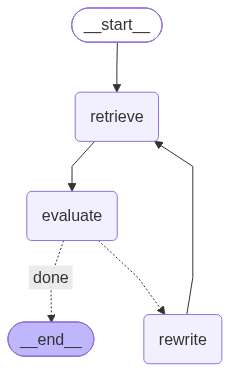

In [45]:
from IPython.display import Image, display

display(
    Image(
        agentic_retriever.get_graph().draw_mermaid_png()
    )
)

# PHASE 6 — Final GovScheme AI Application

In [46]:
from langchain_core.messages import HumanMessage



def generate_answer(query, documents):

    context = "\n\n".join(
        f"Source: {doc.metadata['source']}\n"
        f"Page: {doc.metadata['page']}\n"
        f"{doc.page_content}"
        for doc in documents
    )

    prompt = f"""
You are GovScheme AI, an assistant that helps users understand
Indian government schemes.

Answer the user's question using only the provided government
documents.

If the documents do not contain enough information, clearly say
that sufficient information was not found.

User question:
{query}

Government documents:
{context}

Give a clear and practical answer.
Mention the relevant scheme names and eligibility/benefits when available.
"""
    
    return llm.invoke(prompt).content




In [47]:
def ask_govscheme(query, thread_id="default"):

    config = {
        "configurable": {
            "thread_id": thread_id
        }
    }

    
    state = agentic_retriever.get_state(config)

    previous_messages = state.values.get("messages", [])

  
    if previous_messages:

        history = "\n".join(
            f"{message.type}: {message.content}"
            for message in previous_messages[-6:]
        )

        rewrite_prompt = f"""
Convert the user's latest question into a standalone search query
using the conversation context.

Conversation:
{history}

Latest question:
{query}

Return only the standalone search query.
"""

        search_query = llm.invoke(rewrite_prompt).content.strip()

    else:
        search_query = query


    
    result = agentic_retriever.invoke(
        {
            "messages": [HumanMessage(content=query)],
            "query": search_query,
            "retry_count": 0
        },
        config=config
    )


    # Generate final answer
    answer = generate_answer(
        search_query,
        result["documents"]
    )

    return answer, result["documents"]